# Medicare Claims Intelligence

**Forecasting, fraud/waste/abuse detection, an explainable high-cost risk model, and a guarded RAG assistant, built on public CMS Medicare claims and CDC surveillance data.**

| | Question | Approach | Result |
|---|---|---|---|
| 1 | Can the claims data be trusted? | dbt + DuckDB warehouse, 26 data tests | Found 11,253 outpatient claims with no service date and a cohort artifact (utilization falls ~70% during 2010 while membership falls ~5%) |
| 2 | How many outpatient ILI visits should we staff for 1-4 weeks out? | Harmonic regression + ARIMA errors, STL + ETS, Prophet; 35-origin rolling backtest | **MASE 0.62** vs 1.06 for seasonal naive (Diebold-Mariano p < 0.05 at 1-3 weeks); 88% coverage of 80% intervals |
| 3 | Which providers should program integrity review? | Robust z (MAD), MCD Mahalanobis, Isolation Forest, max-rank ensemble; validated on injected schemes | **81% precision** at a 2% review capacity (random: 2%) |
| 4 | Who will be in next year's top 5% of cost, and why? | Out-of-time XGBoost vs baselines, calibration, SHAP, PSI drift, MLflow registry | Reaches **21.0%** of next year's high-cost members vs 14.4% for prior-year cost (**+46%**) |
| 5 | Can analysts query the docs and data safely? | BM25 + TF-IDF hybrid retrieval (RRF), labeled retrieval eval, tool-using agent with guardrails | **Recall@3 0.86**; SQL tool blocks member identifiers and suppresses counts of 1-10 |

**Data**

- **CMS 2008-2010 Medicare DE-SynPUF, Sample 1:** synthetic fee-for-service claims released by CMS (116K beneficiaries, 790K outpatient claims, 66K inpatient claims, 5.5M Part D events), in the same layout as CMS research files. It is synthetic, so findings describe the method rather than the Medicare population.
- **CDC ILINet** via the Delphi Epidata API: weekly national outpatient influenza-like-illness visits, 2010-2026.
- **DE-SynPUF Codebook and User Manual:** 159 PDF pages, used as the retrieval corpus.

Setup: `pip install -r requirements.txt`, `python scripts/download_data.py`, `dbt build --project-dir dbt --profiles-dir dbt`.

In [1]:
import json, logging, os, re, subprocess, warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
logging.getLogger("prophet").setLevel(logging.WARNING)
logging.getLogger("mlflow").setLevel(logging.WARNING)
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, DOCS = ROOT / "data" / "raw", ROOT / "data" / "docs"
WAREHOUSE = ROOT / "data" / "warehouse.duckdb"
RNG = np.random.default_rng(42)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
print("project root:", ROOT.name)

project root: medicare-claims-intelligence


---
## 1. Claims warehouse and data quality

Raw CSVs become typed, keyed staging views and analysis marts in dbt (DuckDB). Two modeling decisions matter for every downstream number:

- **Claim key = `(CLM_ID, SEGMENT)`.** Long institutional claims are split into segments, and keying on `CLM_ID` alone fans out joins and double-counts payments. A dbt `unique` test enforces the composite key.
- **Exposure.** Utilization is reported per 1,000 members in force, $1000 \cdot 12 \cdot \#\text{claims} / \text{member-months}$, so changes in membership are not mistaken for changes in health.

```
raw CSVs ─► stg_beneficiary ─┬─► mart_members_in_force ─► mart_daily_claims
            stg_outpatient ──┼─► mart_provider_features
            stg_inpatient  ──┼─► mart_member_year ─► mart_risk_dataset
            stg_rx_events  ──┘
```

In [2]:
# Build the warehouse if it does not exist yet (about 1 minute). Re-run `dbt build` after editing models.
import shutil
if not WAREHOUSE.exists():
    out = subprocess.run(
        [shutil.which("dbt") or str(ROOT / ".venv/bin/dbt"), "build", "--project-dir", "dbt", "--profiles-dir", "dbt"],
        cwd=ROOT, capture_output=True, text=True)
    print(out.stdout[-1500:])

con = duckdb.connect(str(WAREHOUSE), read_only=True)
con.execute(f"SET file_search_path = '{ROOT}'")   # staging views read data/raw relative to the project root
q = lambda sql: con.sql(sql).df()
q("select table_name, table_type from information_schema.tables order by 1")

,table_name,table_type
0,mart_daily_claims,BASE TABLE
1,mart_member_year,BASE TABLE
2,mart_members_in_force,BASE TABLE
3,mart_provider_features,BASE TABLE
4,mart_risk_dataset,BASE TABLE
5,stg_beneficiary,VIEW
6,stg_inpatient_claims,VIEW
7,stg_outpatient_claims,VIEW
8,stg_rx_events,VIEW


In [3]:
# Read dbt's own test results: the two warnings are real findings about the data.
results = json.loads((ROOT / "dbt/target/run_results.json").read_text())["results"]
tests = pd.DataFrame([{"test": r["unique_id"].split(".")[2], "status": r["status"], "failures": r.get("failures")}
                      for r in results if r["unique_id"].startswith("test.")])
print(tests.status.value_counts().to_dict())
tests[tests.status != "pass"]

{'pass': 24, 'warn': 2}


,test,status,failures
1,assert_claims_within_coverage_window,warn,1
3,not_null_stg_outpatient_claims_claim_from_date,warn,11253


The two warnings are findings, not noise: **11,253 outpatient claims have no service date** (a daily rollup would silently drop them), and some claims start before the 2008 coverage window. Negative payments (adjustments) stay under the 0.5% alert threshold.

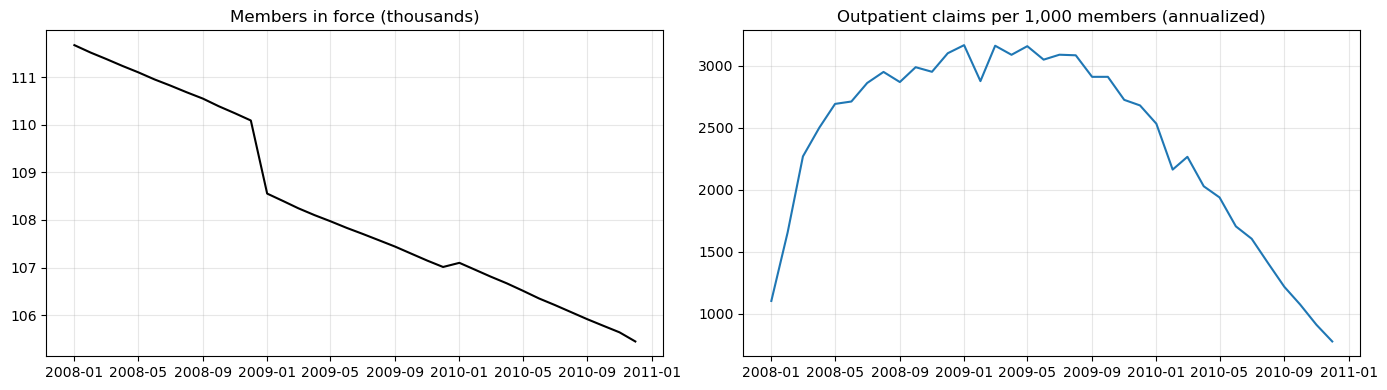

,members_in_force,op_claims,op_per_1000_annual,pmpm_op_ip
claim_date,,,,
2008-01-01,111676,10256,1102.0,155.1
2008-07-01,110827,26414,2860.0,267.5
2009-01-01,108555,28633,3165.2,272.7
2009-07-01,107709,27717,3088.0,258.5
2010-01-01,107099,22594,2531.6,224.4
2010-07-01,106213,14193,1603.5,142.7
2010-12-01,105446,6812,775.2,38.4


In [4]:
mif = q("select * from mart_members_in_force order by month_start").set_index("month_start")
daily = q("select * from mart_daily_claims order by claim_date").set_index("claim_date")
monthly = daily.resample("MS").agg({"op_claims": "sum", "op_paid": "sum", "ip_claims": "sum", "ip_paid": "sum"})
monthly = monthly.join(mif)
monthly["op_per_1000_annual"] = 1000 * 12 * monthly.op_claims / monthly.members_in_force
monthly["pmpm_op_ip"] = (monthly.op_paid + monthly.ip_paid) / monthly.members_in_force

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(monthly.index, monthly.members_in_force / 1e3, color="black")
ax[0].set_title("Members in force (thousands)")
ax[1].plot(monthly.index, monthly.op_per_1000_annual, color="tab:blue")
ax[1].set_title("Outpatient claims per 1,000 members (annualized)")
plt.tight_layout(); plt.show()
monthly[["members_in_force", "op_claims", "op_per_1000_annual", "pmpm_op_ip"]].iloc[[0, 6, 12, 18, 24, 30, 35]].round(1)

**Finding: the 2010 decline is a data artifact.** Membership falls about 5% over three years, but outpatient utilization per 1,000 falls about 70% during 2010, and 2008 opens with a ramp-up. The CMS User Manual explains why: the file is a 2008 cohort whose claims were synthesized from donor beneficiaries, so the edges of the window are not representative. In production this pattern usually signals claims lag or a broken feed, and the right response is to flag it rather than model it. Two design choices follow: forecasting uses a series with genuine seasonality (Section 2), and the risk label is relative (top 5% within each year), so it is robust to level shifts (Section 4).

---
## 2. Forecasting outpatient ILI volume with rolling-origin backtests

**Problem.** A care-navigation or urgent-care operator staffs to expected respiratory visits. We forecast national **%ILI** (ILI visits / all visits; the reporting-provider count doubled since 2010, so the rate removes the exposure change) 1-4 weeks ahead with 80% prediction intervals. Staffing plans use the upper bound, so interval coverage matters as much as accuracy.

**Models** (all fit on log %ILI, because flu seasons are multiplicative):

- **Dynamic harmonic regression:** $y_t = \beta_0 + \sum_{k=1}^{4}\big[a_k \sin(2\pi k t/52.18) + b_k \cos(2\pi k t/52.18)\big] + \eta_t$, with $\eta_t \sim \text{ARMA}(2,1)$. Fourier terms carry the annual cycle, which avoids an unstable 52-lag seasonal ARIMA.
- **STL + ETS:** a robust seasonal-trend decomposition, then damped-trend exponential smoothing on the seasonally adjusted series.
- **Prophet:** piecewise-linear trend with sparse changepoints plus Fourier yearly seasonality.
- **Seasonal naive:** $\hat y_{t+h} = y_{t+h-52}$, the benchmark every model must beat.

**Evaluation.** Expanding-window rolling origins every 4 weeks over the last three seasons (Oct 2023 - Jun 2026). Each forecast uses only data available at its origin.

$$\text{MASE} = \frac{\frac1H\sum_h |y_{T+h}-\hat y_{T+h}|}{\frac{1}{T-m}\sum_{t=m+1}^{T}|y_t - y_{t-m}|}, \qquad S_\alpha(L,U;y) = (U-L) + \tfrac{2}{\alpha}(L-y)\mathbb 1[y<L] + \tfrac{2}{\alpha}(y-U)\mathbb 1[y>U]$$

plus empirical coverage of the 80% intervals, and a Diebold-Mariano test with a Newey-West variance (multi-step errors are autocorrelated) to check whether the best model's advantage is more than luck.

2010-01-03 to 2026-09-27 | 874 weeks


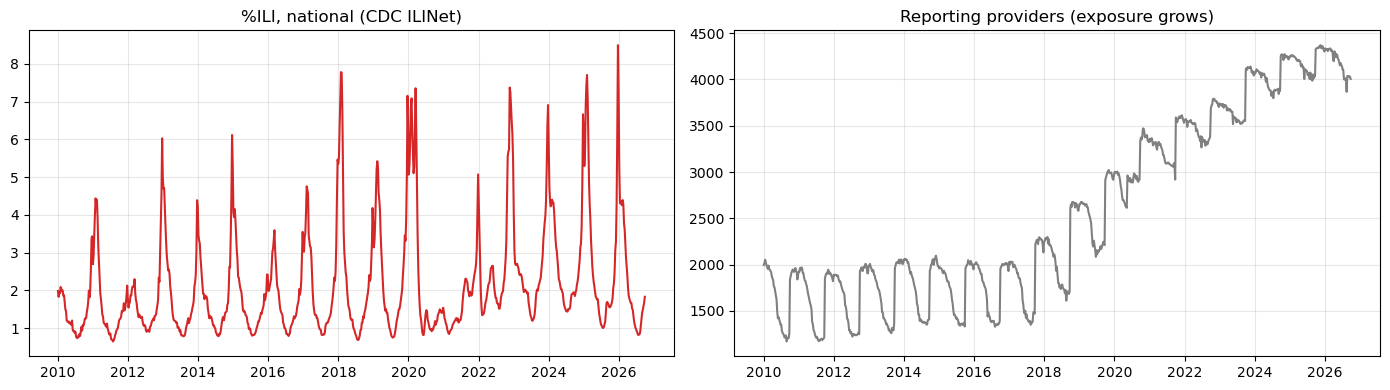

In [5]:
# Load CDC ILINet (national, weekly). Epiweeks start on Sunday; week 1 is the week containing Jan 4.
def epiweek_to_date(ew):
    year, week = divmod(int(ew), 100)
    jan4 = pd.Timestamp(year=year, month=1, day=4)
    return jan4 - pd.Timedelta(days=(jan4.dayofweek + 1) % 7) + pd.Timedelta(weeks=week - 1)

ili_path = RAW / "ilinet_national.json"
if not ili_path.exists():   # public API, no key needed
    import urllib.request
    urllib.request.urlretrieve("https://api.delphi.cmu.edu/epidata/fluview/?regions=nat&epiweeks=201001-202652", ili_path)
ili = pd.DataFrame(json.loads(ili_path.read_text())["epidata"])
ili["week"] = ili.epiweek.map(epiweek_to_date)
ili = ili.set_index("week").sort_index()[["num_ili", "num_patients", "num_providers", "ili"]]
y = ili["ili"].asfreq("W-SUN").interpolate()        # % of visits that are ILI
print(ili.index.min().date(), "to", ili.index.max().date(), "|", len(y), "weeks")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(y, color="tab:red"); ax[0].set_title("%ILI, national (CDC ILINet)")
ax[1].plot(ili.num_providers, color="gray"); ax[1].set_title("Reporting providers (exposure grows)")
plt.tight_layout(); plt.show()

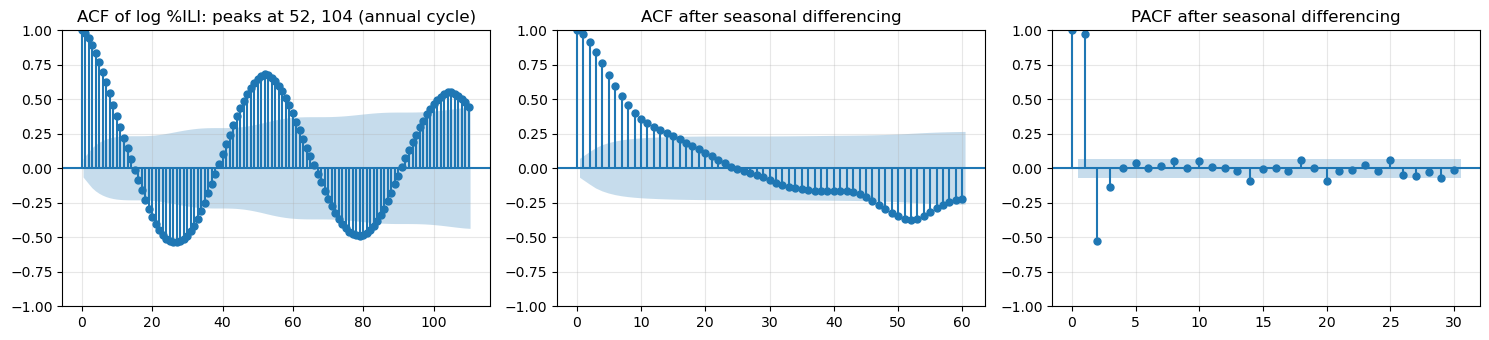

In [6]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
ly = np.log(y)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
plot_acf(ly, lags=110, ax=ax[0], title="ACF of log %ILI: peaks at 52, 104 (annual cycle)")
plot_acf(ly.diff(52).dropna(), lags=60, ax=ax[1], title="ACF after seasonal differencing")
plot_pacf(ly.diff(52).dropna(), lags=30, ax=ax[2], method="ywm", title="PACF after seasonal differencing")
plt.tight_layout(); plt.show()

The raw ACF is dominated by the annual cycle (lags 52 and 104). After seasonal differencing, the PACF cuts off after about two lags, which motivates the AR(2) error term. COVID-19 suppressed the 2020-2021 seasons. They stay in training, and the backtest shows whether each model copes.

In [7]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.forecasting.stl import STLForecast
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from prophet import Prophet
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.simplefilter("ignore", ConvergenceWarning)
logging.getLogger("cmdstanpy").disabled = True             # Prophet's Stan backend is chatty

H, ALPHA, M = 4, 0.20, 52       # horizon (weeks), 80% intervals, season length
Z = 1.2815515655446004          # z_{0.9}

def fourier(t, K=4, period=365.25 / 7):
    return np.column_stack([f(2 * np.pi * k * t / period) for k in range(1, K + 1) for f in (np.sin, np.cos)])

def fc_seasonal_naive(train, h):
    resid = (np.log(train) - np.log(train).shift(M)).dropna()
    sd = resid.std()                                   # spread of same-week-last-year errors
    mean = np.log(train.iloc[-M:-M + h].values)        # y_{T+h} = y_{T+h-52}
    return np.exp(mean), np.exp(mean - Z * sd), np.exp(mean + Z * sd)

def fc_harmonic_arima(train, h, K=4):
    t = np.arange(len(train))
    model = SARIMAX(np.log(train.values), exog=fourier(t, K), order=(2, 0, 1), trend="c").fit(disp=False)
    pred = model.get_forecast(h, exog=fourier(np.arange(len(train), len(train) + h), K))
    lo, hi = pred.conf_int(alpha=ALPHA).T
    return np.exp(pred.predicted_mean), np.exp(lo), np.exp(hi)

def fc_stl_ets(train, h):
    stl = STLForecast(np.log(train), ETSModel, period=M, robust=True,
                      model_kwargs=dict(error="add", trend="add", damped_trend=True)).fit()
    frame = stl.get_prediction(start=len(train), end=len(train) + h - 1).summary_frame(alpha=ALPHA)
    return np.exp(frame["mean"].values), np.exp(frame["mean_ci_lower"].values), np.exp(frame["mean_ci_upper"].values)

def fc_prophet(train, h):
    m = Prophet(yearly_seasonality=10, weekly_seasonality=False, daily_seasonality=False,
                interval_width=1 - ALPHA, uncertainty_samples=200)
    m.fit(pd.DataFrame({"ds": train.index, "y": np.log(train.values)}))
    np.random.seed(0)                                   # Prophet samples its intervals; seed for reproducibility
    fut = m.predict(m.make_future_dataframe(h, freq="W-SUN").tail(h))
    return np.exp(fut.yhat.values), np.exp(fut.yhat_lower.values), np.exp(fut.yhat_upper.values)

MODELS = {"seasonal_naive": fc_seasonal_naive, "harmonic_arima": fc_harmonic_arima,
          "stl_ets": fc_stl_ets, "prophet": fc_prophet}

In [8]:
def scale_mase(train, m=M):
    return np.mean(np.abs(train.values[m:] - train.values[:-m]))

def interval_score(lo, hi, obs, alpha=ALPHA):
    return (hi - lo) + 2 / alpha * (lo - obs) * (obs < lo) + 2 / alpha * (obs - hi) * (obs > hi)

origins = y.index[(y.index >= "2023-10-01") & (y.index <= "2026-06-01")][::4]
rows = []
warnings.simplefilter("ignore")
for origin in origins:
    train = y[:origin]
    actual = y[origin:].iloc[1:H + 1]
    if len(actual) < H:
        continue
    scale = scale_mase(train)
    for name, fn in MODELS.items():
        mean, lo, hi = fn(train, H)
        for h in range(H):
            rows.append(dict(origin=origin, model=name, h=h + 1, actual=actual.iloc[h], pred=mean[h],
                             lo=lo[h], hi=hi[h], abs_err=abs(actual.iloc[h] - mean[h]), scale=scale))
bt = pd.DataFrame(rows)
bt["covered"] = (bt.actual >= bt.lo) & (bt.actual <= bt.hi)
bt["winkler"] = interval_score(bt.lo, bt.hi, bt.actual)
print(f"{bt.origin.nunique()} origins x {bt.model.nunique()} models x {H} horizons = {len(bt)} forecasts")

35 origins x 4 models x 4 horizons = 560 forecasts


In [9]:
summary = (bt.groupby("model")
             .apply(lambda g: pd.Series({"MASE": g.abs_err.mean() / g.scale.mean(),
                                         "MAE": g.abs_err.mean(),
                                         "coverage_80": g.covered.mean(),
                                         "winkler_80": g.winkler.mean()}))
             .sort_values("MASE"))
by_h = bt.pivot_table(index="model", columns="h", values="abs_err", aggfunc="mean")
by_h_cov = bt.pivot_table(index="model", columns="h", values="covered", aggfunc="mean")
display(summary.round(3)); display(by_h.round(3).add_prefix("MAE h=")); display(by_h_cov.round(2).add_prefix("cover h="))

,MASE,MAE,coverage_80,winkler_80
model,,,,
harmonic_arima,0.619,0.461,0.879,2.559
prophet,0.685,0.510,0.957,2.476
seasonal_naive,1.058,0.787,0.957,3.686
stl_ets,1.204,0.896,0.479,6.065


h,MAE h=1,MAE h=2,MAE h=3,MAE h=4
model,,,,
harmonic_arima,0.234,0.421,0.551,0.638
prophet,0.492,0.442,0.501,0.603
seasonal_naive,0.776,0.748,0.809,0.816
stl_ets,0.802,0.883,0.891,1.007


h,cover h=1,cover h=2,cover h=3,cover h=4
model,,,,
harmonic_arima,0.91,0.89,0.86,0.86
prophet,0.97,0.97,0.97,0.91
seasonal_naive,0.97,0.94,0.97,0.94
stl_ets,0.34,0.43,0.54,0.60


In [10]:
from scipy import stats

def diebold_mariano(e_a, e_b, h=1, power=1):
    # DM test on |e|^power with a Newey-West variance using h-1 lags (Harvey et al. small-sample correction).
    d = np.abs(e_a) ** power - np.abs(e_b) ** power
    n, dbar = len(d), d.mean()
    gamma = [np.sum((d[k:] - dbar) * (d[:n - k] - dbar)) / n for k in range(h)]
    var = (gamma[0] + 2 * sum(gamma[1:])) / n
    dm = dbar / np.sqrt(var)
    dm *= np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return dm, 2 * stats.t.sf(abs(dm), df=n - 1)

best = summary.index[0]
for h in range(1, H + 1):
    a = bt[(bt.model == best) & (bt.h == h)].sort_values("origin")
    b = bt[(bt.model == "seasonal_naive") & (bt.h == h)].sort_values("origin")
    dm, p = diebold_mariano((a.actual - a.pred).values, (b.actual - b.pred).values, h=h)
    print(f"h={h}: {best} vs seasonal_naive  DM={dm:6.2f}  p={p:.4f}")

h=1: harmonic_arima vs seasonal_naive  DM= -3.59  p=0.0010
h=2: harmonic_arima vs seasonal_naive  DM= -3.52  p=0.0013
h=3: harmonic_arima vs seasonal_naive  DM= -2.44  p=0.0199
h=4: harmonic_arima vs seasonal_naive  DM= -1.07  p=0.2916


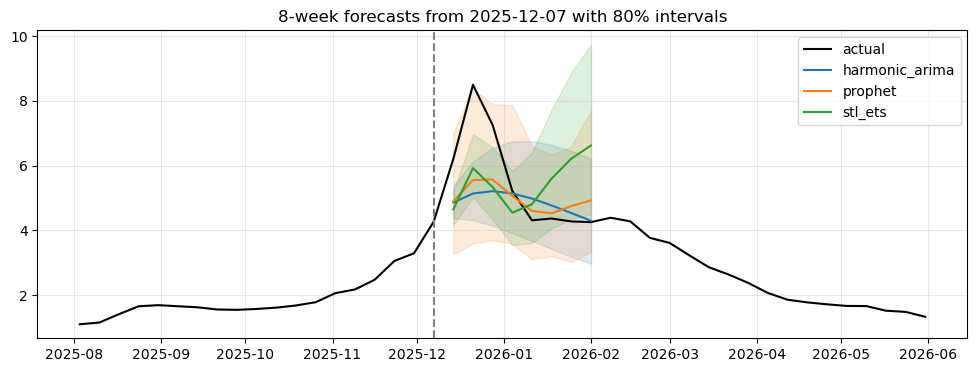

In [11]:
# Forecast fan for the last season, from a single origin, plus the realized path.
origin = pd.Timestamp("2025-12-07")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y["2025-08":"2026-05"], color="black", label="actual")
for name, color in [("harmonic_arima", "tab:blue"), ("prophet", "tab:orange"), ("stl_ets", "tab:green")]:
    mean, lo, hi = MODELS[name](y[:origin], 8)
    idx = pd.date_range(origin, periods=9, freq="W-SUN")[1:]
    ax.plot(idx, mean, color=color, label=name); ax.fill_between(idx, lo, hi, color=color, alpha=0.15)
ax.axvline(origin, color="gray", ls="--"); ax.set_title("8-week forecasts from 2025-12-07 with 80% intervals"); ax.legend()
plt.show()

In [12]:
# Log the backtest to MLflow so every model version and its scores are reproducible.
import mlflow
logging.getLogger("mlflow").setLevel(logging.WARNING)                  # mlflow resets its logger on import
mlflow.set_tracking_uri(f"sqlite:///{ROOT / 'mlflow.db'}")
mlflow.set_experiment("ili_forecasting_backtest")
for name, r in summary.iterrows():
    with mlflow.start_run(run_name=name):
        mlflow.log_params({"model": name, "horizon": H, "interval": 1 - ALPHA, "n_origins": bt.origin.nunique(),
                           "transform": "log", "first_origin": str(origins[0].date())})
        mlflow.log_metrics({k: float(v) for k, v in r.items()})
print("logged", len(summary), "runs; browse with: mlflow ui --backend-store-uri sqlite:///mlflow.db")

logged 4 runs; browse with: mlflow ui --backend-store-uri sqlite:///mlflow.db


### Results

| Model | MASE | 80% coverage | Assessment |
|---|---|---|---|
| **Harmonic regression + ARIMA(2,0,1)** | **0.62** | 0.88 | Best point forecasts; beats seasonal naive at h = 1-3 (DM p < 0.05), not at h = 4 |
| Prophet | 0.69 | 0.96 | Close second; intervals over-cover (wider than needed) |
| Seasonal naive | 1.06 | 0.96 | Benchmark; flu peaks shift by weeks from year to year |
| STL + ETS | 1.20 | 0.48 | Worse than the benchmark, and its intervals are far too narrow |

- Error grows with the horizon (MAE 0.23 at h = 1 to 0.64 at h = 4), and by four weeks out the advantage over "same week last year" is no longer significant. Recommendation: use the model for 1-3 week staffing and treat week 4 as directional.
- Coverage is a separate question from accuracy. Planning on STL + ETS upper bounds would leave staff short about half the time; Prophet's conservative intervals would over-staff. Conformalizing the intervals (rescaling by backtest error quantiles per horizon) is the next step before production.
- The backtest uses final, revised ILINet values. In real time, recent weeks are revised upward as late reports arrive, so a production backtest should use as-of data vintages (the API's `issues` parameter).

---
## 3. Provider anomaly detection for fraud, waste, and abuse

**Problem.** A program-integrity team can review about 2% of providers. We rank the 4,516 attending physicians with 30+ outpatient claims so that the top of the list holds as many real problems as possible. There are no fraud labels, which is the normal situation.

**Features** (from `mart_provider_features`, log-transformed): claims per member, mean and median paid, share of claims above the global 95th percentile, share zero-paid, codes and diagnoses per claim, weekend share, same-day repeat share, facilities, claims per active day.

**Detectors**

- **Robust z-score:** $z = 0.6745\,(x - \text{median}) / \text{MAD}$, which stays reliable when outliers inflate the mean and SD. When MAD = 0 (most providers have *zero* same-day repeats), the scale falls back to the mean absolute deviation, $E|X-\mu| = 0.7979\,\sigma$. Without the fallback the detector is blind to duplicate billing.
- **Mahalanobis distance with Minimum Covariance Determinant:** $D^2 = (x-\hat\mu)^\top\hat\Sigma^{-1}(x-\hat\mu)$, with $\hat\mu, \hat\Sigma$ fit on the most concentrated half of the data so outliers cannot mask themselves. It catches unusual *combinations* of features.
- **Isolation Forest:** score $s = 2^{-E[h(x)]/c(n)}$, where $h$ is the path length to isolate a point in random trees and $c(n) = 2H(n-1) - 2(n-1)/n$.
- **Max-rank ensemble:** flag if *any* detector is very confident. This keeps each detector's specialty; averaging ranks would dilute a signal only one detector sees.

**Validation without labels.** Copies of 90 real providers (2%) receive one of three known schemes: upcoding (paid x1.5-2.5 and more high-paid claims), phantom billing (claims per member and per day x2-3), and duplicate billing (same-day repeats +0.2-0.4). Detectors are scored on precision at review capacity and average precision. The random baseline for both is the 2% prevalence, not the 0.5 that ROC AUC suggests.

In [13]:
prov = q("select * from mart_provider_features order by attending_npi").set_index("attending_npi")   # fixed order = reproducible sampling
FEATURES = ["claims_per_member", "mean_paid", "median_paid", "share_high_paid", "share_zero_paid",
            "mean_hcpcs_codes", "mean_diagnoses", "share_weekend", "share_same_day_repeat",
            "n_facilities", "claims_per_active_day"]
print(prov.shape)
prov[FEATURES].describe(percentiles=[0.5, 0.99]).T.round(3)

(4516, 15)


,count,mean,std,min,50%,99%,max
claims_per_member,4516.0,1.467,0.657,1.000,1.250,4.132,12.200
mean_paid,4516.0,272.102,84.238,72.955,262.438,526.359,828.710
median_paid,4516.0,75.734,16.305,30.000,75.000,100.000,300.000
share_high_paid,4516.0,0.050,0.034,0.000,0.046,0.156,0.290
share_zero_paid,4516.0,0.042,0.027,0.000,0.038,0.121,0.178
mean_hcpcs_codes,4516.0,4.878,1.160,2.161,4.744,8.665,13.355
mean_diagnoses,4516.0,2.656,0.267,1.733,2.647,3.358,4.194
share_weekend,4516.0,0.287,0.061,0.067,0.286,0.452,0.526
share_same_day_repeat,4516.0,0.001,0.006,0.000,0.000,0.032,0.067
n_facilities,4516.0,1.292,0.694,1.000,1.000,4.000,8.000


In [14]:
def inject_schemes(df, rate=0.02, seed=7):
    # Copy a random 2% of real providers and apply one scheme to each copy. Returns data + labels.
    rng = np.random.default_rng(seed)
    n_inj = int(rate * len(df))
    base = df.sample(n_inj, random_state=seed).copy()
    schemes = rng.choice(["upcoding", "phantom", "duplicate"], size=n_inj)
    for i, (idx, s) in enumerate(zip(base.index, schemes)):
        if s == "upcoding":
            k = rng.uniform(1.5, 2.5)
            base.loc[idx, ["mean_paid", "median_paid"]] *= k
            base.loc[idx, "share_high_paid"] = min(1, base.loc[idx, "share_high_paid"] + rng.uniform(0.2, 0.4))
        elif s == "phantom":
            k = rng.uniform(2, 3)
            base.loc[idx, ["claims_per_member", "claims_per_active_day"]] *= k
        else:
            base.loc[idx, "share_same_day_repeat"] = min(1, base.loc[idx, "share_same_day_repeat"] + rng.uniform(0.2, 0.4))
    base.index = [f"INJ{i:04d}_{s}" for i, s in enumerate(schemes)]
    out = pd.concat([df.assign(is_injected=0, scheme="none"), base.assign(is_injected=1, scheme=schemes)])
    return out

pop = inject_schemes(prov[FEATURES])
X = np.log1p(pop[FEATURES].clip(lower=0))        # log scale: billing features are right-skewed
print(pop.is_injected.sum(), "injected among", len(pop), "| schemes:", pop.query("is_injected == 1").scheme.value_counts().to_dict())

90 injected among 4606 | schemes: {'duplicate': 34, 'phantom': 30, 'upcoding': 26}


In [15]:
from sklearn.covariance import MinCovDet
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score

med = X.median()
mad = (X - med).abs().median()
mean_ad = (X - med).abs().mean()
# MAD = 0 when most providers share one value (e.g. 0 same-day repeats); fall back to the mean absolute
# deviation, scaled so it also estimates sigma for normal data: E|X - mu| = sigma * sqrt(2/pi) = 0.7979 sigma.
scale = (mad / 0.6745).where(mad > 0, mean_ad / 0.7979)
robust_z = ((X - med) / scale).fillna(0)
print("features with MAD = 0:", list(mad[mad == 0].index))

scores = pd.DataFrame(index=X.index)
scores["robust_z_max"] = robust_z.abs().max(axis=1)                     # most extreme single behavior
mcd = MinCovDet(random_state=0).fit(X)
scores["mahalanobis_mcd"] = mcd.mahalanobis(X)                          # D^2, joint unusualness
iso = IsolationForest(n_estimators=500, max_samples=256, random_state=0).fit(X)
scores["isolation_forest"] = -iso.score_samples(X)                      # = s(x, n): higher is more anomalous
scores["rank_ensemble_max"] = scores.rank(pct=True).max(axis=1)         # flag if ANY detector is very confident

def precision_recall_at_k(score, label, k):
    top = score.sort_values(ascending=False).index[:k]
    hits = label.loc[top].sum()
    return hits / k, hits / label.sum()

k = int(pop.is_injected.sum())     # review capacity = 2% of providers
res = []
for name in scores:
    p, r = precision_recall_at_k(scores[name], pop.is_injected, k)
    res.append(dict(detector=name, **{f"precision@{k}": p, f"recall@{k}": r,
                    "avg_precision": average_precision_score(pop.is_injected, scores[name])}))
fwa_results = pd.DataFrame(res).set_index("detector")
print("random baseline average precision =", round(pop.is_injected.mean(), 3))
fwa_results.round(3)

features with MAD = 0: ['share_same_day_repeat', 'n_facilities']


random baseline average precision = 0.02


,precision@90,recall@90,avg_precision
detector,,,
robust_z_max,0.722,0.722,0.836
mahalanobis_mcd,0.622,0.622,0.576
isolation_forest,0.556,0.556,0.576
rank_ensemble_max,0.811,0.811,0.816


In [16]:
# Recall by scheme: each detector is blind to some schemes.
top = {name: set(scores[name].sort_values(ascending=False).index[:k]) for name in scores}
inj = pop.query("is_injected == 1")
pd.DataFrame({name: inj.groupby("scheme").apply(lambda g: np.mean([i in top[name] for i in g.index]))
              for name in scores}).round(2)

,robust_z_max,mahalanobis_mcd,isolation_forest,rank_ensemble_max
scheme,,,,
duplicate,1.00,0.0,0.53,1.00
phantom,1.00,1.0,0.67,1.00
upcoding,0.04,1.0,0.46,0.35


In [17]:
# Explain a flag the way an investigator needs it: which behaviors are extreme versus peers?
def c(n): return 2 * (np.log(n - 1) + 0.5772156649) - 2 * (n - 1) / n
print("c(256) = %.2f expected path length for a normal point; s=0.5 at that depth" % c(256))

real_flags = scores.loc[pop.is_injected == 0, "isolation_forest"].sort_values(ascending=False).head(3).index
for npi in real_flags:
    zs = robust_z.loc[npi].sort_values(key=np.abs, ascending=False).head(3)
    print(f"provider {npi}: " + ", ".join(f"{f} z={v:+.1f}" for f, v in zs.items()))

c(256) = 10.24 expected path length for a normal point; s=0.5 at that depth
provider 3019816555: median_paid z=+9.6, mean_hcpcs_codes z=+5.3, n_facilities z=+5.2
provider 3565091883: share_same_day_repeat z=+11.3, mean_hcpcs_codes z=+5.1, share_high_paid z=+4.4
provider 1315933224: claims_per_member z=+12.3, share_high_paid z=+5.2, mean_hcpcs_codes z=+3.8


In [18]:
# Benford's law on outpatient paid amounts: P(first digit = d) = log10(1 + 1/d).
amounts = q("select paid_amount from stg_outpatient_claims where paid_amount >= 10").paid_amount
first = amounts.astype(int).astype(str).str[0].astype(int)
obs = first.value_counts(normalize=True).sort_index()
benford = pd.Series(np.log10(1 + 1 / np.arange(1, 10)), index=range(1, 10))
chi2 = len(first) * (((obs - benford) ** 2) / benford).sum()
mad_benford = (obs - benford).abs().mean()
print(f"chi2 = {chi2:,.0f} (df=8) | mean abs deviation = {mad_benford:.4f}  (Nigrini: > 0.015 = nonconformity)")
pd.DataFrame({"observed": obs, "benford": benford}).T.round(3)

chi2 = 27,731 (df=8) | mean abs deviation = 0.0175  (Nigrini: > 0.015 = nonconformity)


,1,2,3,4,5,6,7,8,9
observed,0.234,0.164,0.131,0.109,0.092,0.098,0.060,0.061,0.051
benford,0.301,0.176,0.125,0.097,0.079,0.067,0.058,0.051,0.046


### Results

- The **max-rank ensemble reaches 81% precision at review capacity**: 73 of the top 90 flags are planted schemes, against 2% for random review.
- The detectors are complementary. The robust z-score catches every duplicate and phantom scheme but loses upcoding among naturally expensive providers. Mahalanobis catches every upcoding and phantom scheme because it sees the *combination* of higher paid amounts and more high-paid claims, but it misses duplicates, since a feature that is almost always 0 barely registers in a covariance fit.
- Each flag ships with its most extreme robust z-scores, the plain-language reason an investigator needs (for example "claims per member z = +12.3").
- **Benford's law** is not a useful population-level test here: amounts are rounded to $10 and fee schedules concentrate payments on a few values. It belongs at the provider level, against peers.
- Limitation: schemes are injected at the feature level. Injecting at the claim level and rebuilding the features in SQL is the more realistic next validation.

---
## 4. Explainable high-cost risk model

**Problem.** Care management can contact about 5% of members. Predict who will be in the **top 5% of Medicare cost next year**: prospective risk stratification.

**Design**

- **Prospective and out-of-time:** features from year $t$, label from $t+1$. Train on 2008 to 2009 (114,538 members), test on 2009 to 2010 (112,754). A random split would leak members and periods across train and test.
- **Relative label:** top 5% within each year, robust to the 2010 level artifact.
- **Baselines first:** prior-year cost (the standard payer baseline) and chronic-condition count.
- **Metrics:** ROC AUC, PR AUC (baseline 0.05), and **capture**: the share of next year's high-cost members found in the top-5% outreach list, which is the operational metric. Reliability curve and Brier score for calibration.

**Explanation with SHAP.** For features $F$ and value function $v(S) = E_{X_{\bar S}}[f(x_S, X_{\bar S})]$ (interventional), the Shapley value

$$\phi_i = \sum_{S\subseteq F\setminus\{i\}} \frac{|S|!\,(|F|-|S|-1)!}{|F|!}\big[v(S\cup\{i\}) - v(S)\big]$$

is the unique attribution satisfying efficiency ($\sum_i\phi_i = f(x) - E f(X)$), symmetry, dummy, and additivity. TreeSHAP computes it exactly for tree ensembles. SHAP describes what the model relies on, not causal effects.

In [19]:
risk = q("select * from mart_risk_dataset order by year, member_id")   # fixed order = reproducible training
RISK_FEATURES = ["age", "sex_code", "has_esrd", "part_a_months", "part_b_months", "hmo_months", "part_d_months",
                 "cc_alzhdmta", "cc_chf", "cc_chrnkidn", "cc_cncr", "cc_copd", "cc_depressn", "cc_diabetes",
                 "cc_ischmcht", "cc_osteoprs", "cc_ra_oa", "cc_strketia", "n_chronic_conditions",
                 "ip_admits", "ip_days", "op_visits", "op_distinct_physicians", "rx_fills", "rx_cost",
                 "rx_days_supply", "medicare_paid_ip", "medicare_paid_op", "medicare_paid_car",
                 "medicare_paid_total", "member_responsibility"]
risk[RISK_FEATURES] = risk[RISK_FEATURES].astype(float)
train, test = risk[risk.year == 2008], risk[risk.year == 2009]
Xtr, ytr = train[RISK_FEATURES], train.is_high_cost_next_year.astype(int)
Xte, yte = test[RISK_FEATURES], test.is_high_cost_next_year.astype(int)
print(f"train {len(train):,} members (2008 -> 2009) | test {len(test):,} members (2009 -> 2010) | prevalence {ytr.mean():.3f} / {yte.mean():.3f}")

train 114,538 members (2008 -> 2009) | test 112,754 members (2009 -> 2010) | prevalence 0.050 / 0.050


In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.metrics import roc_auc_score, brier_score_loss
import xgboost as xgb

def evaluate(name, score, y, top_frac=0.05):
    cut = np.quantile(score, 1 - top_frac)
    flagged = score >= cut
    return dict(model=name, roc_auc=roc_auc_score(y, score), pr_auc=average_precision_score(y, score),
                capture_top5=y[flagged].sum() / y.sum(), precision_top5=y[flagged].mean())

logit = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=2000, C=0.5))
logit.fit(Xtr.clip(lower=0), ytr)

XGB_PARAMS = dict(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                  min_child_weight=20, reg_lambda=1.0, eval_metric="aucpr", random_state=0, n_jobs=4)
booster = xgb.XGBClassifier(**XGB_PARAMS).fit(Xtr, ytr)

p_logit = logit.predict_proba(Xte.clip(lower=0))[:, 1]
p_xgb = booster.predict_proba(Xte)[:, 1]
risk_results = pd.DataFrame([
    evaluate("baseline: last-year cost", Xte.medicare_paid_total.values, yte.values),
    evaluate("baseline: chronic count", Xte.n_chronic_conditions.values + 1e-6 * Xte.medicare_paid_total.values, yte.values),
    evaluate("logistic regression", p_logit, yte.values),
    evaluate("xgboost", p_xgb, yte.values),
]).set_index("model")
risk_results.round(3)

,roc_auc,pr_auc,capture_top5,precision_top5
model,,,,
baseline: last-year cost,0.708,0.104,0.144,0.144
baseline: chronic count,0.717,0.102,0.134,0.134
logistic regression,0.739,0.154,0.201,0.201
xgboost,0.744,0.178,0.210,0.210


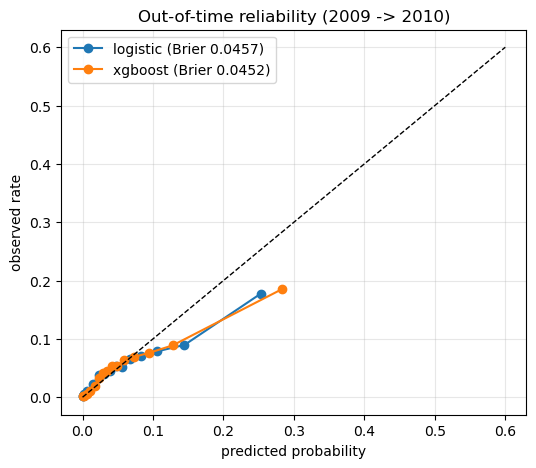

mean predicted 0.0569 vs observed 0.0500


In [21]:
from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(figsize=(6, 5))
for name, p in [("logistic", p_logit), ("xgboost", p_xgb)]:
    frac_pos, mean_pred = calibration_curve(yte, p, n_bins=15, strategy="quantile")
    ax.plot(mean_pred, frac_pos, "o-", label=f"{name} (Brier {brier_score_loss(yte, p):.4f})")
ax.plot([0, 0.6], [0, 0.6], "k--", lw=1); ax.set_xlabel("predicted probability"); ax.set_ylabel("observed rate")
ax.set_title("Out-of-time reliability (2009 -> 2010)"); ax.legend(); plt.show()
print("mean predicted %.4f vs observed %.4f" % (p_xgb.mean(), yte.mean()))

In [22]:
import shap
# Validation: brute-force the Shapley formula on a 4-feature model and confirm TreeSHAP matches it exactly.
from itertools import combinations
from math import factorial
small_feats = ["ip_admits", "medicare_paid_total", "n_chronic_conditions", "rx_cost"]
small = xgb.XGBClassifier(n_estimators=50, max_depth=3, random_state=0).fit(Xtr[small_feats], ytr)
background = Xtr[small_feats].sample(100, random_state=1)   # TreeSHAP subsamples >100 rows; keep 100 so both use the same background
x = Xte[small_feats].iloc[[0]]
margin = lambda df: small.predict(df, output_margin=True)

def v(S):
    data = background.copy()
    for f in S:
        data[f] = x[f].values[0]
    return margin(data).mean()          # interventional value function E[f(x_S, X_notS)]

M_ = len(small_feats)
brute = []
for i in small_feats:
    others = [f for f in small_feats if f != i]
    brute.append(sum(factorial(len(S)) * factorial(M_ - len(S) - 1) / factorial(M_) * (v(S + (i,)) - v(S))
                     for r in range(M_) for S in combinations(others, r)))
tree_phi = shap.TreeExplainer(small, data=background, feature_perturbation="interventional",
                              model_output="raw").shap_values(x)[0]
print(pd.DataFrame({"brute_force": brute, "tree_shap": tree_phi}, index=small_feats).round(5))
print("efficiency: sum(phi) = %.5f, f(x) - E f(X) = %.5f" % (sum(brute), margin(x)[0] - margin(background).mean()))

                      brute_force  tree_shap
ip_admits                -0.02204   -0.02204
medicare_paid_total      -0.13719   -0.13719
n_chronic_conditions     -0.47071   -0.47071
rx_cost                  -0.10743   -0.10743
efficiency: sum(phi) = -0.73737, f(x) - E f(X) = -0.73737


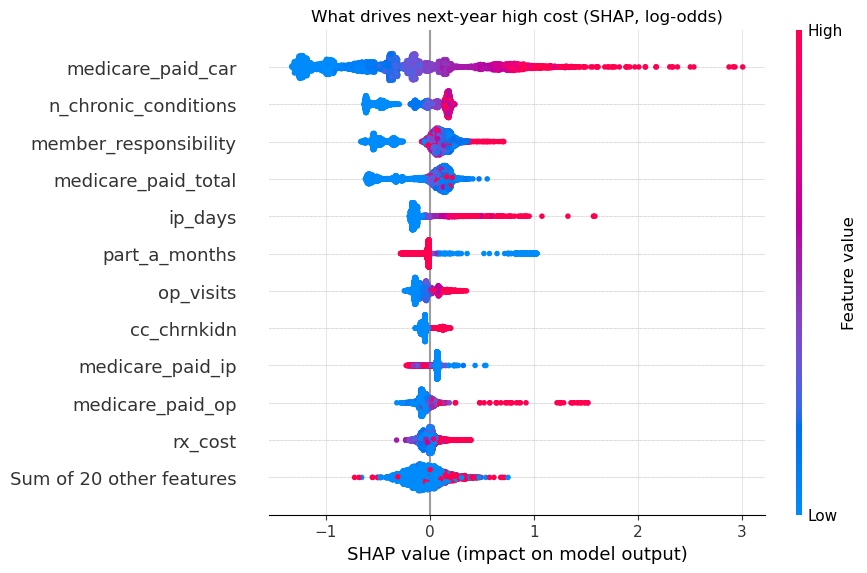

medicare_paid_car        0.631
n_chronic_conditions     0.254
member_responsibility    0.194
medicare_paid_total      0.191
ip_days                  0.159
part_a_months            0.096
op_visits                0.095
cc_chrnkidn              0.078
Name: mean |SHAP|, dtype: float32

In [23]:
explainer = shap.TreeExplainer(booster)
sample = Xte.sample(5000, random_state=0)
sv = explainer(sample)                              # log-odds contributions
shap.plots.beeswarm(sv, max_display=12, show=False); plt.title("What drives next-year high cost (SHAP, log-odds)"); plt.show()
pd.Series(np.abs(sv.values).mean(0), index=sample.columns).sort_values(ascending=False).head(8).round(3).rename("mean |SHAP|")

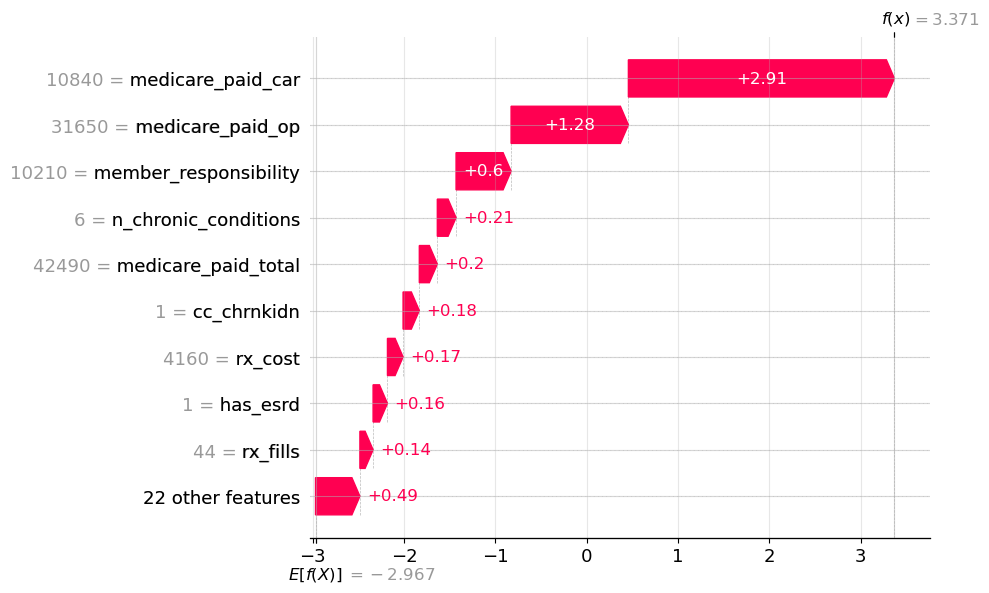

In [24]:
# Local explanation for one member the model ranks highest: the "why" a care manager reads.
top_member = sample.index[np.argmax(booster.predict_proba(sample)[:, 1])]
i = list(sample.index).index(top_member)
shap.plots.waterfall(sv[i], max_display=10, show=False); plt.show()

In [25]:
# Monitoring: Population Stability Index between the training (2008) and scoring (2009) feature distributions.
def psi(expected, actual, bins=10):
    # PSI = sum (a - e) * ln(a / e) over quantile bins of the expected distribution.
    cuts = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    if len(cuts) < 3:
        return 0.0
    e = np.histogram(np.clip(expected, cuts[0], cuts[-1]), cuts)[0] / len(expected)
    a = np.histogram(np.clip(actual, cuts[0], cuts[-1]), cuts)[0] / len(actual)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))

drift = pd.Series({f: psi(Xtr[f].values, Xte[f].values) for f in RISK_FEATURES}).sort_values(ascending=False)
print("PSI rule of thumb: < 0.1 stable, 0.1-0.25 watch, > 0.25 investigate")
drift.head(8).round(3)

PSI rule of thumb: < 0.1 stable, 0.1-0.25 watch, > 0.25 investigate


rx_fills                  0.205
rx_days_supply            0.191
rx_cost                   0.110
op_visits                 0.062
op_distinct_physicians    0.062
medicare_paid_op          0.053
medicare_paid_total       0.051
member_responsibility     0.048
dtype: float64

In [26]:
# Track the model, its parameters, metrics, and drift report in MLflow, and register it.
mlflow.set_experiment("high_cost_risk")
with mlflow.start_run(run_name="xgboost_oot_2008_2009") as run:
    mlflow.log_params({**XGB_PARAMS, "train_year": 2008, "test_year": 2009, "label": "top 5% paid next year",
                       "n_features": len(RISK_FEATURES)})
    mlflow.log_metrics({k: float(v) for k, v in risk_results.loc["xgboost"].items()})
    mlflow.log_metric("brier", float(brier_score_loss(yte, p_xgb)))
    mlflow.log_metric("max_feature_psi", float(drift.max()))
    mlflow.log_dict(drift.round(4).to_dict(), "drift_psi.json")
    mlflow.xgboost.log_model(booster, name="model", input_example=Xte.head(3),
                             registered_model_name="high_cost_risk")
print("run", run.info.run_id)

run 2770b4a8a6e547adbf1c24ced63bbeee


Successfully registered model 'high_cost_risk'.
Created version '1' of model 'high_cost_risk'.


### Results

| Model | ROC AUC | PR AUC | Top-5% capture |
|---|---|---|---|
| Baseline: prior-year cost | 0.708 | 0.104 | 14.4% |
| Baseline: chronic-condition count | 0.717 | 0.102 | 13.4% |
| Logistic regression | 0.739 | 0.154 | 20.1% |
| **XGBoost** | **0.744** | **0.178** | **21.0%** |

- **Business value:** for the same outreach budget, XGBoost reaches about **46% more** of next year's high-cost members than calling last year's most expensive members.
- **Simplicity trade-off:** logistic regression keeps 95% of the gain. If the production stack cannot support gradient boosting, it is a defensible choice.
- **Calibration:** mean predicted 0.057 vs 0.050 observed in the new year, a slight over-prediction from year-to-year drift. Recalibrate on the latest year before using probabilities for budgeting.
- **Drivers (SHAP):** physician/carrier spend dominates, followed by chronic-condition count, member out-of-pocket responsibility, total paid, and inpatient days. Ongoing physician-managed care and comorbidity burden persist from year to year more reliably than a single hospital stay. TreeSHAP matches the brute-force Shapley values exactly, and the contributions sum to the model output.
- **Monitoring:** Part D features (fills, days supply, cost) drift (PSI 0.11-0.21, "watch"), consistent with Part D enrollment growth from 2008 to 2009. The run, parameters, metrics, drift report, and model are tracked and registered in MLflow.

---
## 5. Documentation RAG and a guarded data agent

**Problem.** Analysts ask "what does this column mean?" and "what was the number?" The assistant answers from the official CMS documentation with page citations, and queries the warehouse under privacy guardrails.

**Retrieval.** One passage per PDF page (157 pages). Three rankers:

- **BM25** (implemented here): $\sum_{t\in q}\text{IDF}(t)\,\frac{f_{t,d}(k_1+1)}{f_{t,d} + k_1(1-b+b\,|d|/\text{avgdl})}$, with $k_1 = 1.2$, $b = 0.75$.
- **TF-IDF cosine.**
- **Hybrid via Reciprocal Rank Fusion:** $\text{RRF}(d) = \sum_r 1/(60 + \text{rank}_r(d))$.

They are evaluated on 14 hand-labeled analyst questions with recall@k, MRR, and nDCG@5. Generation is only as good as retrieval, so retrieval is measured on its own.

**Agent guardrails** (enforced in the tools, not the prompt, so prompt injection cannot bypass them): a single read-only `SELECT` only; results containing member, claim, or event identifiers are blocked; CMS small-cell suppression masks counts of 1-10; a step budget; and "I don't know" when no tool applies. Answers are generated by any OpenAI-compatible endpoint (for example a local Ollama) when `LLM_BASE_URL` is set; otherwise the assistant returns cited extracts. The planner shown is rule-based so the notebook runs offline; an LLM planner returning the same JSON actions plugs into the same loop.

In [27]:
from pypdf import PdfReader
from sklearn.feature_extraction.text import TfidfVectorizer

passages = []      # one passage per PDF page, with its citation
for pdf in ["synpuf_data_users_guide.pdf", "de10_codebook.pdf"]:
    for page_no, page in enumerate(PdfReader(DOCS / pdf).pages, start=1):
        text = " ".join((page.extract_text() or "").split())
        if len(text) > 200:
            passages.append({"doc": pdf.replace(".pdf", ""), "page": page_no, "text": text})
corpus = [p["text"] for p in passages]
cite = lambda i: f'{passages[i]["doc"]} p.{passages[i]["page"]}'
tokenize = lambda s: re.findall(r"[a-z0-9_]+", s.lower())
print(len(passages), "passages")

class BM25:
    def __init__(self, docs, k1=1.2, b=0.75):
        self.toks = [tokenize(d) for d in docs]
        self.k1, self.b = k1, b
        self.len = np.array([len(t) for t in self.toks]); self.avgdl = self.len.mean()
        self.tf = [pd.Series(t).value_counts().to_dict() for t in self.toks]
        df = pd.Series([w for t in self.toks for w in set(t)]).value_counts()
        N = len(docs)
        self.idf = (np.log(1 + (N - df + 0.5) / (df + 0.5))).to_dict()
    def scores(self, query):
        s = np.zeros(len(self.toks))
        for t in set(tokenize(query)):
            idf = self.idf.get(t)
            if idf is None:
                continue
            f = np.array([tf.get(t, 0) for tf in self.tf])
            s += idf * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * self.len / self.avgdl))
        return s

bm25 = BM25(corpus)
tfidf = TfidfVectorizer(sublinear_tf=True, token_pattern=r"[A-Za-z0-9_]+", stop_words="english").fit(corpus)
D = tfidf.transform(corpus)

def rank_bm25(query): return np.argsort(-bm25.scores(query))
def rank_tfidf(query): return np.argsort(-(D @ tfidf.transform([query]).T).toarray().ravel())
def rank_hybrid(query, k=60):
    rrf = np.zeros(len(corpus))
    for ranking in (rank_bm25(query), rank_tfidf(query)):
        rrf[ranking] += 1 / (k + np.arange(1, len(corpus) + 1))
    return np.argsort(-rrf)

157 passages


In [28]:
# A small gold set: plain-English analyst questions -> the pages that answer them (checked by hand).
GOLD = [
    ("How much did the Medicare trust fund pay on an inpatient claim?", {("de10_codebook", 56)}),
    ("annual Medicare reimbursement for inpatient services for a beneficiary", {("de10_codebook", 38)}),
    ("How many months of Part D plan coverage did the beneficiary have?", {("de10_codebook", 26)}),
    ("Which variable indicates end stage renal disease?", {("de10_codebook", 19)}),
    ("How much did the patient pay for a prescription that was not reimbursed by a third party?", {("de10_codebook", 120)}),
    ("gross drug cost of a prescription: ingredient cost and dispensing fee", {("de10_codebook", 121)}),
    ("Which diagnosis related group was the inpatient stay assigned to?", {("de10_codebook", 70)}),
    ("number of covered utilization days on an institutional claim", {("de10_codebook", 68)}),
    ("Should analysts rely on the date of death in the synthetic file?", {("de10_codebook", 16)}),
    ("How many months of HMO coverage did the member have?", {("de10_codebook", 25)}),
    ("How were synthetic beneficiaries created from seed and donor beneficiaries?", {("synpuf_data_users_guide", 17)}),
    ("line-level NCH payment amount on carrier claims", {("de10_codebook", 105)}),
    ("national provider identifier of the performing physician on carrier claims", {("de10_codebook", 102)}),
    ("What sample of Medicare beneficiaries was the DE-SynPUF drawn from?", {("synpuf_data_users_guide", 4), ("de10_codebook", 5)}),
]

def eval_retriever(rank_fn, ks=(1, 3, 5)):
    out = {f"recall@{k}": [] for k in ks}; out["mrr"] = []; out["ndcg@5"] = []
    for question, gold in GOLD:
        ranked = [(passages[i]["doc"], passages[i]["page"]) for i in rank_fn(question)[:50]]
        for k in ks:
            out[f"recall@{k}"].append(len(gold & set(ranked[:k])) / len(gold))
        first = next((r for r, d in enumerate(ranked, 1) if d in gold), None)
        out["mrr"].append(1 / first if first else 0)
        dcg = sum(1 / np.log2(i + 2) for i, d in enumerate(ranked[:5]) if d in gold)
        idcg = sum(1 / np.log2(i + 2) for i in range(min(len(gold), 5)))
        out["ndcg@5"].append(dcg / idcg)
    return {k: np.mean(v) for k, v in out.items()}

rag_results = pd.DataFrame({name: eval_retriever(fn) for name, fn in
                            [("bm25", rank_bm25), ("tfidf_cosine", rank_tfidf), ("hybrid_rrf", rank_hybrid)]}).T
rag_results.round(3)

,recall@1,recall@3,recall@5,mrr,ndcg@5
bm25,0.714,0.786,0.857,0.774,0.778
tfidf_cosine,0.643,0.786,0.857,0.737,0.754
hybrid_rrf,0.714,0.857,0.857,0.781,0.786


In [29]:
def answer(question, k=3, llm=None):
    # Grounded answer: retrieve, then either let an LLM write from the passages or return cited extracts.
    top = rank_hybrid(question)[:k]
    context = "\n\n".join(f"[{cite(i)}] {passages[i]['text'][:1200]}" for i in top)
    if llm is None:
        return "Top passages:\n" + "\n".join(f"- [{cite(i)}] {passages[i]['text'][:220]}..." for i in top)
    prompt = ("Answer using ONLY the passages. Cite pages like [de10_codebook p.56]. "
              "If the passages do not contain the answer, say you don't know.\n\n"
              f"Passages:\n{context}\n\nQuestion: {question}")
    return llm(prompt)

def openai_compatible_llm(prompt):
    # Works with any OpenAI-compatible endpoint, e.g. a local Ollama (LLM_BASE_URL=http://localhost:11434/v1).
    import urllib.request
    body = json.dumps({"model": os.environ.get("LLM_MODEL", "llama3.2:3b"), "temperature": 0,
                       "messages": [{"role": "user", "content": prompt}]}).encode()
    req = urllib.request.Request(os.environ["LLM_BASE_URL"].rstrip("/") + "/chat/completions", data=body,
                                 headers={"Content-Type": "application/json",
                                          "Authorization": f"Bearer {os.environ.get('LLM_API_KEY', 'none')}"})
    return json.loads(urllib.request.urlopen(req, timeout=120).read())["choices"][0]["message"]["content"]

LLM = openai_compatible_llm if os.environ.get("LLM_BASE_URL") else None
print("LLM:", "connected" if LLM else "none (showing cited extracts; set LLM_BASE_URL to generate answers)")
print(answer("What does the claim payment amount on an outpatient claim represent?", llm=LLM))

LLM: none (showing cited extracts; set LLM_BASE_URL to generate answers)
Top passages:
- [de10_codebook p.85] CMS Linkable 2008–2010 Medicare DE-SynPUF CODEBOOK | 81 clotting factors). Adjustments to the payment may occur due to short–stay outliers, interrupted stays, high cost outliers, wage index, and cost of living adjustment...
- [de10_codebook p.57] CMS Linkable 2008–2010 Medicare DE-SynPUF CODEBOOK | 53 clotting factors). Adjustments to the payment may occur due to short–stay outliers, interrupted stays, high cost outliers, wage index, and cost of living adjustment...
- [de10_codebook p.84] CMS Linkable 2008–2010 Medicare DE-SynPUF CODEBOOK | 80 OP-7. Label: DESYNPUF: Claim Payment Amount Variable Name: CLM_PMT_AMT33 Source ■ File: 2008 – 2010: outpatient files ■ Variable: clm_pmt_amt ■ Label: Claim Payment...


In [30]:
# Tools with guardrails. The SQL tool is read-only, blocks identifiers, and suppresses small cells.
FORBIDDEN = re.compile(r"\b(insert|update|delete|drop|create|alter|attach|copy|pragma|install|load|export|read_csv|read_parquet)\b", re.I)
IDENTIFIERS = {"member_id", "claim_id", "claim_key", "pde_id"}
MIN_CELL = 11

def sql_tool(query):
    if not re.match(r"^\s*(select|with)\b", query, re.I) or ";" in query.strip().rstrip(";") or FORBIDDEN.search(query):
        return {"error": "blocked: only a single read-only SELECT is allowed"}
    df = con.sql(query).df()
    leaked = IDENTIFIERS & {c.lower() for c in df.columns}
    if leaked:
        return {"error": f"blocked: result exposes identifiers {sorted(leaked)}"}
    for col in [c for c in df.columns if re.search(r"(^n$|^n_|count|members|claims)", c, re.I)]:
        small = df[col].between(1, MIN_CELL - 1)
        df.loc[small, col] = np.nan                                # CMS small-cell suppression
    return {"rows": df.head(20).to_dict("records")}

def docs_tool(question):
    return {"passages": [{"cite": cite(i), "text": passages[i]["text"][:300]} for i in rank_hybrid(question)[:2]]}

TOOLS = {"sql": sql_tool, "docs": docs_tool}

print(sql_tool("select member_id, medicare_paid_total from mart_member_year limit 3"))
print(sql_tool("drop table mart_member_year"))
print(sql_tool("select state_code, count(*) as n_members from mart_member_year where year = 2010 and has_esrd group by 1 order by 2 limit 5"))

{'error': "blocked: result exposes identifiers ['member_id']"}
{'error': 'blocked: only a single read-only SELECT is allowed'}
{'rows': [{'state_code': '09', 'n_members': nan}, {'state_code': '53', 'n_members': 11.0}, {'state_code': '02', 'n_members': 14.0}, {'state_code': '47', 'n_members': 17.0}, {'state_code': '35', 'n_members': 20.0}]}


In [31]:
# The agent loop. `plan` decides the next tool call from the question and the observations so far.
# Here `plan` is a transparent rule-based policy so the notebook runs offline; swap in an LLM that
# returns the same JSON ({"tool": ..., "input": ...} or {"final": ...}) and the loop is unchanged.
SQL_TEMPLATES = {
    r"total .*outpatient.* paid .*(20\d\d)": "select sum(paid_amount) as op_paid from stg_outpatient_claims where year(claim_from_date) = {0}",
    r"how many members .*(chf|diabetes|copd).* (20\d\d)": "select count(*) as n_members from mart_member_year where cc_{0} and year = {1}",
}

def plan(question, observations):
    if not observations and re.search(r"\b(what does|mean|definition|defined)\b", question, re.I):
        return {"tool": "docs", "input": re.split(r",? and |\?", question)[0]}   # look up only the definition clause
    for pattern, template in SQL_TEMPLATES.items():
        m = re.search(pattern, question, re.I)
        if m and not any(o["tool"] == "sql" for o in observations):
            return {"tool": "sql", "input": template.format(*[g.lower() for g in m.groups()])}
    if observations:
        return {"final": " | ".join(f"{o['tool']}: {str(o['output'])[:200]}" for o in observations)}
    return {"final": "I don't know: no tool can answer this question."}

def run_agent(question, max_steps=4, verbose=True):
    observations = []
    for step in range(1, max_steps + 1):
        action = plan(question, observations)
        if "final" in action:
            if verbose: print(f"step {step}: FINAL -> {action['final'][:400]}")
            return action["final"]
        output = TOOLS[action["tool"]](action["input"])
        observations.append({"tool": action["tool"], "input": action["input"], "output": output})
        if verbose: print(f"step {step}: {action['tool']}({action['input'][:90]!r})")
    return "stopped: step budget exhausted"

run_agent("What does CLM_PMT_AMT mean, and what was the total outpatient paid in 2009?")
print()
run_agent("How many members had CHF in 2009?")
print()
run_agent("Which provider is committing fraud?")

step 1: docs('What does CLM_PMT_AMT mean')


step 2: sql('select sum(paid_amount) as op_paid from stg_outpatient_claims where year(claim_from_date) ')
step 3: FINAL -> docs: {'passages': [{'cite': 'de10_codebook p.84', 'text': 'CMS Linkable 2008–2010 Medicare DE-SynPUF CODEBOOK | 80 OP-7. Label: DESYNPUF: Claim Payment Amount Variable Name: CLM_PMT_AMT33 Source ■ File: 20 | sql: {'rows': [{'op_paid': 87972330.0}]}

step 1: sql('select count(*) as n_members from mart_member_year where cc_chf and year = 2009')
step 2: FINAL -> sql: {'rows': [{'n_members': 39438.0}]}

step 1: FINAL -> I don't know: no tool can answer this question.


"I don't know: no tool can answer this question."

### Results

- **Hybrid retrieval is best:** recall@3 0.86, MRR 0.78, nDCG@5 0.79. BM25 alone is close, because exact identifiers such as `CLM_PMT_AMT` are rare, high-IDF tokens.
- The agent answers a compound question in two tool calls: it cites the codebook page that defines `CLM_PMT_AMT`, then queries total 2009 outpatient payments. It refuses a question no tool can answer.
- The guardrails hold: a query that selects `member_id` is blocked, a `DROP` is blocked, and a state with fewer than 11 ESRD members is suppressed.

---
## Next steps

1. Conformalize the forecast intervals and backtest on ILINet data vintages.
2. Inject FWA schemes at the claim level, and add peer groups by specialty and facility type.
3. Recalibrate the risk model on the latest year, and report grouped SHAP (inpatient, outpatient, pharmacy, chronic conditions).
4. Swap the rule-based planner for an LLM planner and measure tool-choice accuracy.
5. Schedule `dbt build` → forecast → FWA scoring → risk scoring → monitoring as one monthly DAG (Airflow or Databricks Workflows).